# Two-layer network from scratch
Implementation and explanations by Alejandro.

In [173]:
import pandas as pd
import numpy as np

df_cancer = pd.read_csv("../data/breast_cancer.csv")

df_cancer.head()
df_cancer.describe()

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,symmetry_mean,fractal_dimension_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst,target
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,0.627417
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,0.483918
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,0.000000
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,0.000000
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,1.000000
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,1.000000
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,1.000000


In [174]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

y = df_cancer[['target']]
X = df_cancer.drop(columns=['target'])

X_train, X_test, y_train, y_test = train_test_split(X.to_numpy(),y.to_numpy(),test_size=0.2, stratify=y)

# Do  normalization of the values.
mms = MinMaxScaler()
X_train = mms.fit_transform(X_train)
X_test = mms.transform(X_test)


In [175]:
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

(455, 30) (114, 30) (455, 1) (114, 1)


# create MLP class and implement layers and neurons

In [176]:
def sigmoid(Z):
    return 1/(1+np.exp(-Z))

def tanh(Z):
    # return (np.exp(Z)-np.exp(-Z))/(np.exp(Z)+np.exp(-Z))
    return np.tanh(Z)

# droppping this idea temporarily to focus on 2 layers
# class Layer:
#     def __init__(self, neurons, seed=42):
#         np.random.default_rng(seed)
#         self.neurons = neurons
#         self.W = [np.random.normal(0,1, neurons) 
#                   for neuron in range(neurons)]

class TwoLayerMLP:
    def __init__(self,layers=[5,1], feature_count=1, lr= 0.01, seed = 42):
        # self.layers = [Layer(neurons) for neurons in hidden_layers]
        # self.output = Layer(output_layers)
        rng = np.random.default_rng(seed)

        self.W1 = rng.normal(0, 1, size=(layers[0], feature_count)) * 0.01
        self.b1 = np.zeros((layers[0], 1)) #(5,1)

        self.W2 = rng.normal(0,1, size=(layers[1], layers[0])) * .01
        self.b2 = np.zeros((layers[1], 1)) #(5,1)

        self.lr = lr
        self.costs = []

    def cost(self, A, Y):
        #clipping to avoid 0 in log
        cost = -np.mean(Y*np.log(np.clip(A, min=0.000001)) + (1-Y)*(np.log(np.clip(1-A,min=0.000001))))
        self.costs.append(cost)
        return cost


    def forward(self, X):
        # (5,m) @ (nx, m) + (5, 1) = (5,m) broadcast
        Z1 = self.W1 @ X + self.b1
        A1 = tanh(Z1)
        # (1,5) @ (5, 1) + (1, 1)
        Z2 = self.W2 @ A1 + self.b2
        A2 = sigmoid(Z2)

        return A1, A2
    def backward(self, X, Y, params):
        A1, A2 = params

        # (1, m) -  (1, m) = (1, m)
        # print(A2.shape, Y.shape)
        dZ2 = A2 - Y
        # mean (1, m) @ (5, m).T = (m, 1)
        dW2 = dZ2 @ A1.T / X.shape[1]#, axis=1)
        # mean(m,1) = (1,1)
        db2 = np.mean(dZ2, axis=1, keepdims=True)

        # (1, 5).T @ (1, m) = (5,m)
        dA1 = self.W2.T @ dZ2
        # (5, m) * (5, m) =  (5, m) 
        dZ1 = dA1 * (1 - A1 ** 2)
        # mean(5,m) @ (nx, m).T = (5,nx)
        dW1 = dZ1 @ X.T / X.shape[1]
        #  mean(5,m) = (5, 1)
        db1 = np.mean(dZ1, axis=1, keepdims=True)

        return  dW1, db1, dW2, db2

    def update(self, params):
        dW1, db1, dW2, db2 = params

        self.W2 -= dW2 * self.lr
        self.W1 -= dW1 * self.lr

        self.b2 -= db2 * self.lr
        self.b1 -= db1 * self.lr

    def fit(self, X, Y, epochs=1000):
        for e in range(epochs):
            params = self.forward(X)
            self.cost(params[1],Y)
            params = self.backward(X, Y, params)
            self.update(params)


mlp2 = TwoLayerMLP([5,1],len(X_train.T)) 
mlp2.fit(X_train.T, y_train.T)


In [207]:
from sklearn.metrics import precision_recall_fscore_support


rows = []

# simple Hypeparametrization
for lr in [0.001,0.01,0.1,1,1.1]:
    mlp2 = TwoLayerMLP([5,1],len(X_train.T),lr) 
    mlp2.fit(X_train.T, y_train.T)
    # print(lr)
    for THRESHOLD in [
        # 0.4,0.5,
        0.6, 
        # .7,.8
        ]:
        result = {}

        result['lr'] = lr
        result['threshold'] = THRESHOLD

        # print(THRESHOLD)
        A1,A2 = mlp2.forward(X_train.T)
        # print( "Train accuracy: ",
        accuracy_train=    np.mean((A2 > THRESHOLD) == y_train.T)
        # )
        # (y_train.T.mean())

        precision, recall, fscore, support = precision_recall_fscore_support(y_train.ravel(), (A2 > THRESHOLD).T.ravel(), average='binary', zero_division=0)
        result['precision_train'] = precision
        result['recall_train'] = recall
        result['fscore_train']= fscore

        A1,A2 = mlp2.forward(X_test.T)
        # # print(A2.shape, y_test.T.shape)
        # print(
        #     "Test accuracy: ",
        accuracy_test = np.mean((A2 > THRESHOLD) == y_test.T)
        #     # ,y_test.shape
        #     # ,y_test.ravel().shape
        # )
        
        result['accuracy_train'] = accuracy_train
        result['accuracy_test'] = accuracy_test

        precision, recall, fscore, support = precision_recall_fscore_support(y_test.ravel(), (A2 > THRESHOLD).T.ravel(), average='binary', zero_division=0)
        result['precision_test'] = precision
        result['recall_test'] = recall
        result['fscore_test']= fscore

        rows.append(result)

        # print(precision,recall,fscore)
results = pd.DataFrame(rows)
display(results.sort_values(by='fscore_test',ascending=False))


,lr,threshold,precision_train,recall_train,fscore_train,accuracy_train,accuracy_test,precision_test,recall_test,fscore_test
2,0.100,0.6,0.982394,0.978947,0.980668,0.975824,0.982456,1.000000,0.972222,0.985915
4,1.100,0.6,0.986014,0.989474,0.987741,0.984615,0.982456,1.000000,0.972222,0.985915
3,1.000,0.6,0.986014,0.989474,0.987741,0.984615,0.982456,1.000000,0.972222,0.985915
1,0.010,0.6,0.626374,1.000000,0.770270,0.626374,0.631579,0.631579,1.000000,0.774194
0,0.001,0.6,0.000000,0.000000,0.000000,0.373626,0.368421,0.000000,0.000000,0.000000


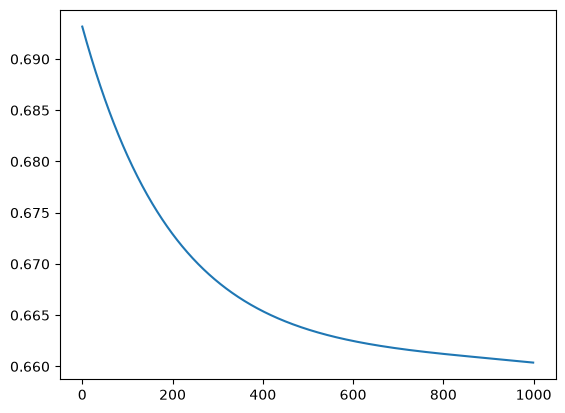

In [178]:
import matplotlib.pyplot as plt


plt.plot(mlp2.costs)

# Verifying Gradients

In [ ]:
W2_original = mlp2.W2[0,0]
params = mlp2.forward(X_train.T)
cost_before = mlp2.cost(params[1], y_train.T)
_,_,dW2_original,_ = mlp2.backward(X_train.T, y_train.T, params)

epsilon = 1e-5
mlp2.W2[0,0] += epsilon
params = mlp2.forward(X_train.T)
cost_after =  mlp2.cost(params[1], y_train.T)
# dW2_after,_,_,_ =  mlp2.backward(X_train.T, y_train.T, params)
# print(W2_original ,mlp2.W2[0,0])
slope = (cost_after - cost_before)/epsilon#(W2_original - mlp2.W2[0,0])

print(f"dW2 original {dW2_original[0,0]}")
# print(f"dW2 after {dW2_after[0,0]}")
print(f"Calculated slope {slope}")
print(f"Diff: {slope - dW2_original[0,0]}")

mlp2.W2[0,0] = W2_original


dW2 original 0.004132315149750183
Calculated slope 0.004132315445382062
Diff: 2.956318792199375e-10
